Aqui voy a empezar a colocar lo que necesitamos para empezar.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

#Esta es la semilla que utilizamos para el deep learning 
SEMILLA = 42
np.random.seed(SEMILLA)

#Funcion para el dataset 

def resumen(df):
    # Ficha técnica por columna: tipo, nulos, cardinalidad y un ejemplo
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "no_nulos": df.notna().sum(),
        "nulos": df.isna().sum(),
        "%_nulos": (df.isna().mean() * 100).round(2),
        "valores_unicos": df.nunique(),
        "ejemplo": df.iloc[0],
    })

In [12]:
RUTA_DATOS = "dataset/Dataset_Mod.csv"
df = pd.read_csv(RUTA_DATOS, sep=";")

# 1. Eliminar la columna vacía generada por el ";" al final de cada línea
df = df.dropna(axis=1, how="all")

# 2. Renombrar las dos primeras columnas para que queden limpias
df = df.rename(columns={
    df.columns[0]: "Week of the month",
    df.columns[1]: "Day of the week"
})

# 3. Corregir los valores de Fiscal sector orders que quedaron sin "0." decimal (unidades vs miles)
mask_enteros = (df["Non-urgent order"] + df["Urgent order"] + df["Fiscal sector orders"] - df["Target (Total orders)"]).abs() > 1
df.loc[mask_enteros, "Fiscal sector orders"] = df.loc[mask_enteros, "Fiscal sector orders"] / 1000.0

print("Dimensiones:", df.shape)
display(df.head())
display(resumen(df))
display(df.describe().T)

Dimensiones: (60, 13)


,Week of the month,Day of the week,Non-urgent order,Urgent order,Order type A,Order type B,Order type C,Fiscal sector orders,Orders from the traffic controller sector,Banking orders (1),Banking orders (2),Banking orders (3),Target (Total orders)
0,1,4,316.307,223.270,61.543,175.586,302.448,0.000,65.556,44.914,188.411,14.793,539.577
1,1,5,128.633,96.042,38.058,56.037,130.580,0.000,40.419,21.399,89.461,7.679,224.675
2,1,6,43.651,84.375,21.826,25.125,82.461,1.386,11.992,3.452,21.305,14.947,129.412
3,2,2,171.297,127.667,41.542,113.294,162.284,18.156,49.971,33.703,69.054,18.423,317.120
4,2,3,90.532,113.526,37.679,56.618,116.220,6.459,48.534,19.646,16.411,20.257,210.517


,tipo,no_nulos,nulos,%_nulos,valores_unicos,ejemplo
Week of the month,int64,60,0,0.0,5,1.000
Day of the week,int64,60,0,0.0,5,4.000
Non-urgent order,float64,60,0,0.0,60,316.307
Urgent order,float64,60,0,0.0,60,223.270
Order type A,float64,60,0,0.0,60,61.543
Order type B,float64,60,0,0.0,60,175.586
Order type C,float64,60,0,0.0,60,302.448
Fiscal sector orders,float64,60,0,0.0,48,0.000
Orders from the traffic controller sector,float64,60,0,0.0,60,65.556
Banking orders (1),float64,60,0,0.0,60,44.914


,count,mean,std,min,25%,50%,75%,max
Week of the month,60.0,3.016667,1.282102,1.000,2.00000,3.0000,4.00000,5.000
Day of the week,60.0,4.033333,1.401775,2.000,3.00000,4.0000,5.00000,6.000
Non-urgent order,60.0,172.554933,69.505788,43.651,125.34800,151.0625,194.60650,435.304
Urgent order,60.0,118.920850,27.170929,77.371,100.88800,113.1145,132.10825,223.270
Order type A,60.0,52.112217,18.829911,21.826,39.45625,47.1665,58.46375,118.178
Order type B,60.0,109.229850,50.741388,25.125,74.91625,99.4820,132.17100,267.342
Order type C,60.0,139.531250,41.442932,74.372,113.63225,127.9900,160.10750,302.448
Fiscal sector orders,60.0,9.397533,23.186188,0.000,0.08950,1.6350,12.52025,169.275
Orders from the traffic controller sector,60.0,44.504350,12.197905,11.992,34.99425,44.3120,52.11175,71.772
Banking orders (1),60.0,46.640833,45.220736,3.452,20.13000,32.5275,45.11875,210.508


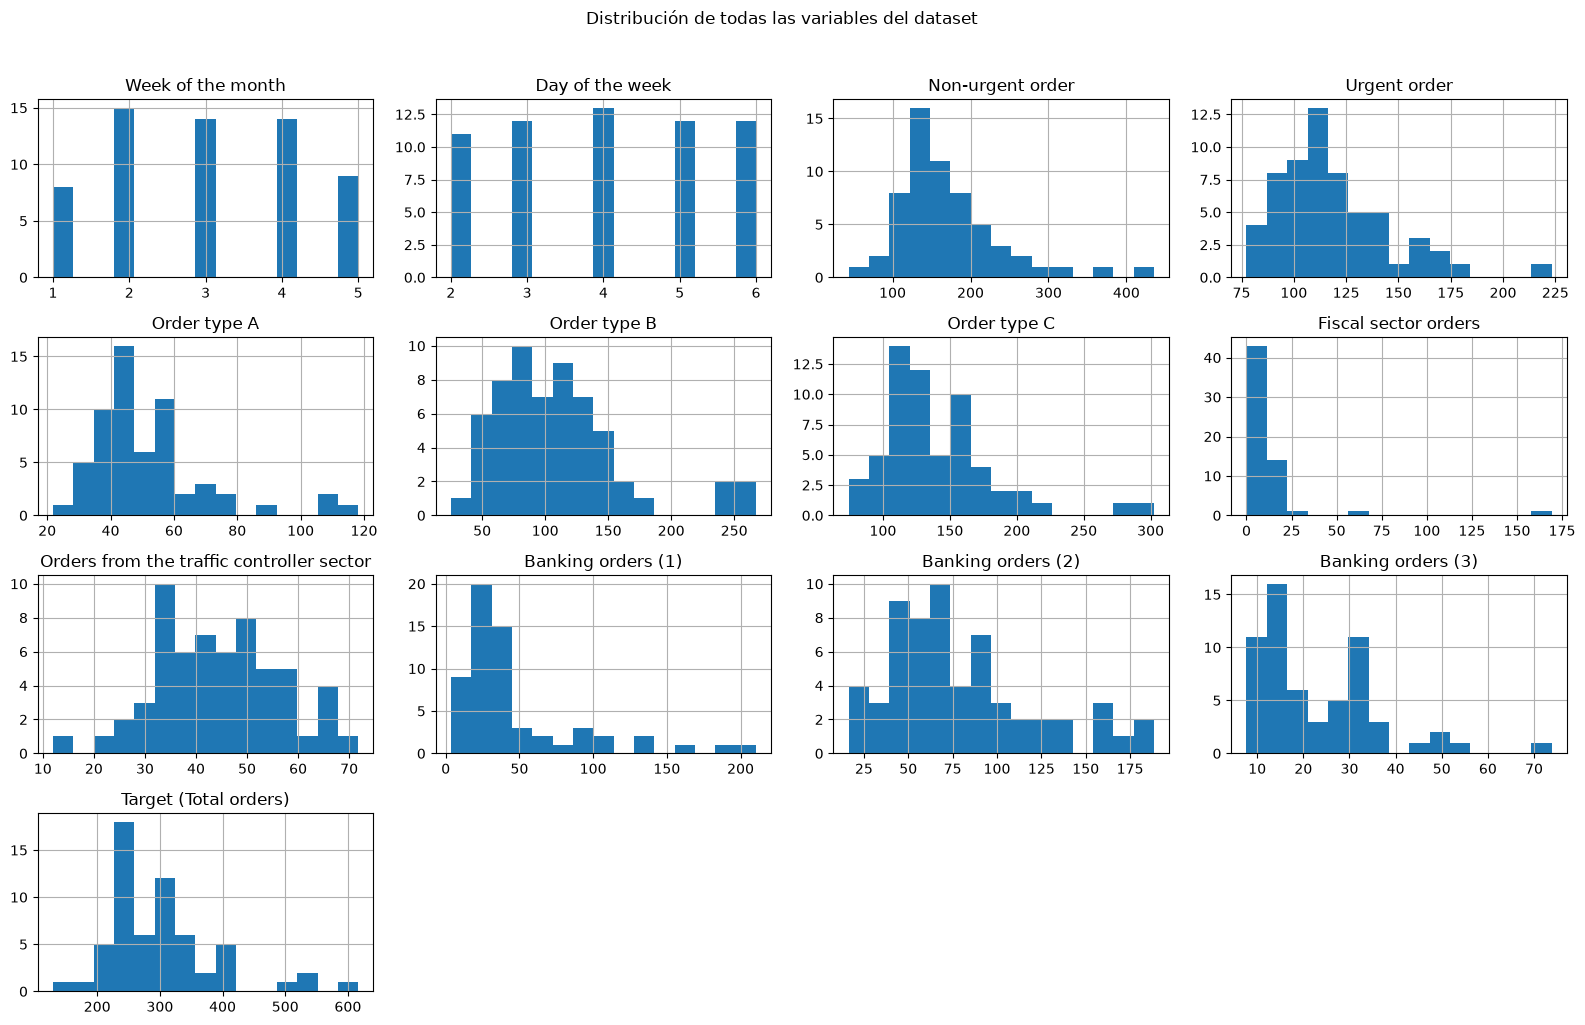

In [14]:
df.hist(bins=15, figsize=(16, 10))
plt.suptitle("Distribución de todas las variables del dataset", y=1.02)
plt.tight_layout()
plt.show()

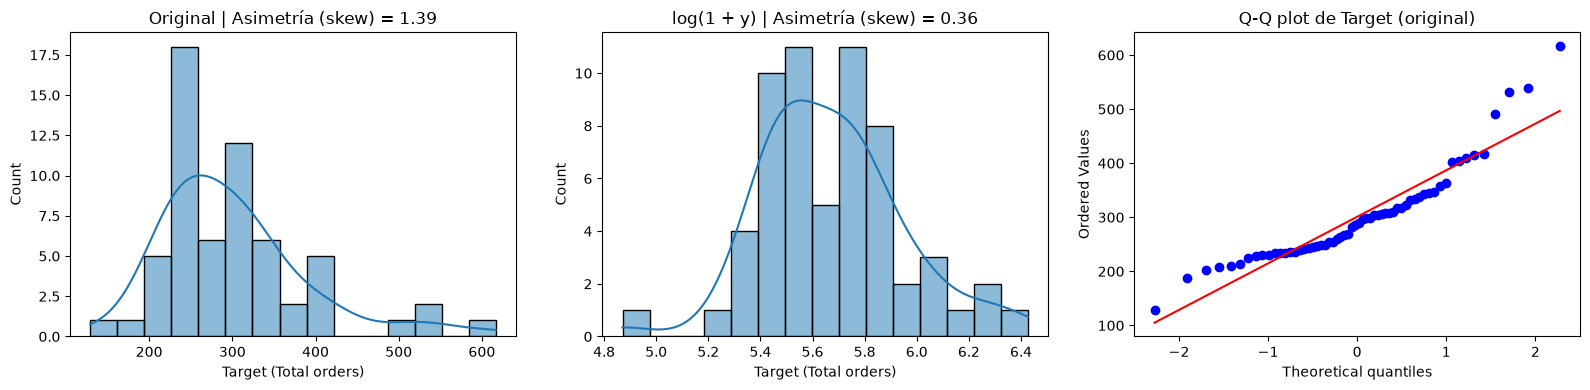

In [15]:
y_target = df["Target (Total orders)"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Distribución original
sns.histplot(y_target, kde=True, bins=15, ax=axes[0])
axes[0].set_title(f"Original | Asimetría (skew) = {y_target.skew():.2f}")

# 2. Distribución con log(1 + y)
sns.histplot(np.log1p(y_target), kde=True, bins=15, ax=axes[1])
axes[1].set_title(f"log(1 + y) | Asimetría (skew) = {np.log1p(y_target).skew():.2f}")

# 3. Q-Q plot
stats.probplot(y_target, dist="norm", plot=axes[2])
axes[2].set_title("Q-Q plot de Target (original)")

plt.tight_layout()
plt.show()

,Asimetría (skew),Outliers_IQR (cant),Outliers_IQR (%),Outliers_Z>3 (%)
Week of the month,0.02,0,0.00,0.00
Day of the week,-0.02,0,0.00,0.00
Non-urgent order,1.55,4,6.67,3.33
Urgent order,1.30,2,3.33,1.67
Order type A,1.72,4,6.67,3.33
Order type B,1.34,4,6.67,3.33
Order type C,1.73,2,3.33,3.33
Fiscal sector orders,5.89,2,3.33,1.67
Orders from the traffic controller sector,0.04,0,0.00,0.00
Banking orders (1),2.04,10,16.67,3.33


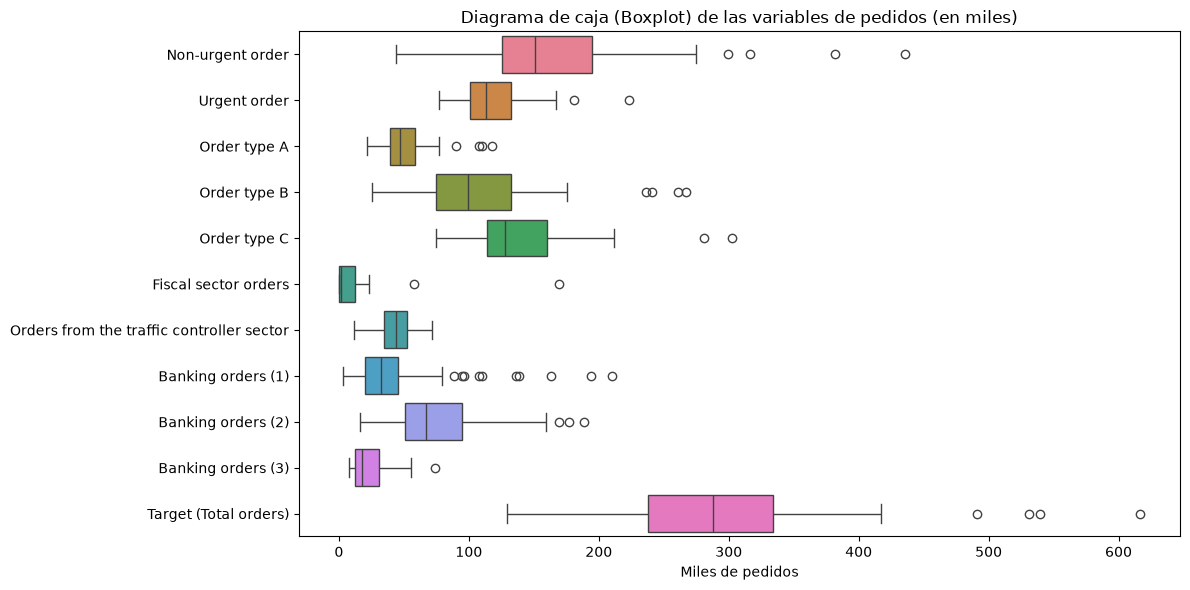

In [16]:
def outliers_iqr(serie, k=1.5):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - k * iqr) | (serie > q3 + k * iqr)

num_cols = df.select_dtypes("number").columns

tabla_outliers = pd.DataFrame({
    "Asimetría (skew)": df[num_cols].skew(),
    "Outliers_IQR (cant)": [outliers_iqr(df[c]).sum() for c in num_cols],
    "Outliers_IQR (%)": [outliers_iqr(df[c]).mean() * 100 for c in num_cols],
    "Outliers_Z>3 (%)": [(np.abs(stats.zscore(df[c])) > 3).mean() * 100 for c in num_cols],
}, index=num_cols)

display(tabla_outliers.round(2))

# Gráfica de Boxplots para visualizar los outliers de las variables de pedidos
cols_pedidos = [c for c in num_cols if c not in ["Week of the month", "Day of the week"]]
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[cols_pedidos], orient="h")
plt.title("Diagrama de caja (Boxplot) de las variables de pedidos (en miles)")
plt.xlabel("Miles de pedidos")
plt.tight_layout()
plt.show()